In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q xgboost

In [3]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

print("Libraries imported successfully")

Libraries imported successfully


In [4]:
diagnostic_path = "/content/drive/MyDrive/AutoSenseAI/data/ML Car Diagnostic Agent AI Assistant.csv"

df = pd.read_csv(diagnostic_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10000, 12)


,Record ID,Car Name,Problem Classification,Problem Description,Severity,Diagnosis,How to Fix the Problem,Solution Used,ECU Data,Service History,Repair Status,Results
0,1,Honda Civic 2019,Electrical,Headlights flicker,Medium,Loose wiring,Check and repair loose or damaged wiring conne...,Check and repair wiring,NaN,Spark plugs replaced 2 years ago,Fixed,Resolved
1,2,Toyota Corolla 2018,Electrical,Power window failure,Medium,Window regulator motor,Check and repair loose or damaged wiring conne...,Check and repair wiring,Multiple codes,Spark plugs replaced 2 years ago,Fixed,Resolved
2,3,BMW i4 2019,Engine,Engine misfire,High,Timing belt failure,Replace spark plugs,Replaced failure,P0101,Regular maintenance,Fixed,Resolved
3,4,Nissan Rogue 2020,Transmission,Transmission overheating,High,Transmission fluid thick,Perform transmission service and inspect for i...,Perform transmission service,NaN,Spark plugs replaced 2 years ago,Fixed,Resolved
4,5,Mercedes S-Class 2020,Battery,Battery drains fast,High,Dead battery,Replace battery and test charging system,Replaced battery,NaN,Brake service 1 year ago,Fixed,Resolved


In [5]:
df["ECU Data"] = df["ECU Data"].fillna("Unknown")
df["Service History"] = df["Service History"].fillna("Unknown")

In [6]:
df["Vehicle_Year"] = pd.to_numeric(
    df["Car Name"].str.extract(r"(\d{4})$")[0],
    errors="coerce"
)

df["Car_Make"] = df["Car Name"].str.split().str[0]

df["Car_Model"] = (
    df["Car Name"]
    .str.replace(r"\s+\d{4}$", "", regex=True)
    .str.split(n=1)
    .str[1]
)

In [7]:
df[
    [
        "Car Name",
        "Car_Make",
        "Car_Model",
        "Vehicle_Year"
    ]
].head()

,Car Name,Car_Make,Car_Model,Vehicle_Year
0,Honda Civic 2019,Honda,Civic,2019
1,Toyota Corolla 2018,Toyota,Corolla,2018
2,BMW i4 2019,BMW,i4,2019
3,Nissan Rogue 2020,Nissan,Rogue,2020
4,Mercedes S-Class 2020,Mercedes,S-Class,2020


In [8]:
features = [
    "Car_Make",
    "Car_Model",
    "Vehicle_Year",
    "Problem Description",
    "Severity",
    "Service History",
    "ECU Data",
    "Diagnosis"
]

target = "Problem Classification"

X = df[features]
y = df[target]

In [9]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Class mapping:")

for cls, encoded in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(cls, "->", encoded)

Class mapping:
Battery -> 0
Brakes -> 1
Electrical -> 2
Engine -> 3
Transmission -> 4


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (8000, 8)
Test: (2000, 8)


In [11]:
categorical_columns = [
    "Car_Make",
    "Car_Model",
    "Problem Description",
    "Severity",
    "Service History",
    "ECU Data",
    "Diagnosis"
]

numerical_columns = [
    "Vehicle_Year"
]

In [12]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns
        )
    ]
)

In [13]:
dummy_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DummyClassifier(
                strategy="most_frequent"
            )
        )
    ]
)

In [14]:
dummy_pipeline.fit(
    X_train,
    y_train
)

dummy_pred = dummy_pipeline.predict(
    X_test
)

In [15]:
dummy_accuracy = accuracy_score(
    y_test,
    dummy_pred
)

dummy_precision = precision_score(
    y_test,
    dummy_pred,
    average="macro",
    zero_division=0
)

dummy_recall = recall_score(
    y_test,
    dummy_pred,
    average="macro",
    zero_division=0
)

dummy_f1 = f1_score(
    y_test,
    dummy_pred,
    average="macro",
    zero_division=0
)

print("DUMMY BASELINE")
print("Accuracy        :", round(dummy_accuracy, 4))
print("Macro Precision :", round(dummy_precision, 4))
print("Macro Recall    :", round(dummy_recall, 4))
print("Macro F1        :", round(dummy_f1, 4))

DUMMY BASELINE
Accuracy        : 0.209
Macro Precision : 0.0418
Macro Recall    : 0.2
Macro F1        : 0.0691


In [16]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [17]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", rf_model)
    ]
)

In [18]:
rf_pipeline.fit(
    X_train,
    y_train
)

print("Random Forest trained successfully")

Random Forest trained successfully


In [19]:
rf_pred = rf_pipeline.predict(
    X_test
)

In [20]:
rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_precision = precision_score(
    y_test,
    rf_pred,
    average="macro",
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_pred,
    average="macro",
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_pred,
    average="macro",
    zero_division=0
)

print("RANDOM FOREST")
print("Accuracy        :", round(rf_accuracy, 4))
print("Macro Precision :", round(rf_precision, 4))
print("Macro Recall    :", round(rf_recall, 4))
print("Macro F1        :", round(rf_f1, 4))

RANDOM FOREST
Accuracy        : 0.973
Macro Precision : 0.9741
Macro Recall    : 0.9735
Macro F1        : 0.9736


In [21]:
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

     Battery       0.95      0.91      0.93       403
      Brakes       1.00      1.00      1.00       410
  Electrical       0.92      0.96      0.94       418
      Engine       1.00      1.00      1.00       392
Transmission       1.00      1.00      1.00       377

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000



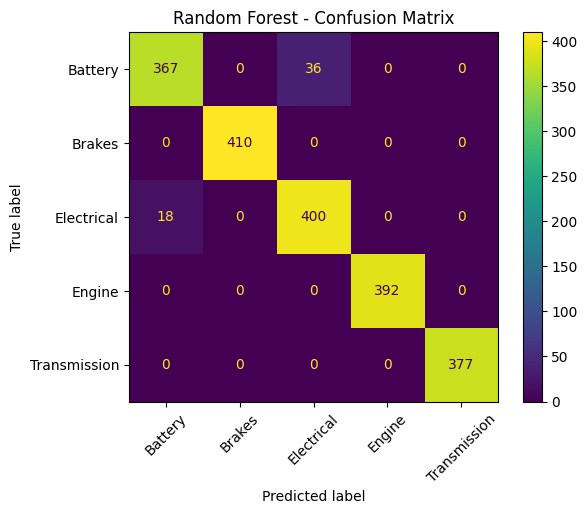

In [22]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=label_encoder.classes_,
    xticks_rotation=45
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [23]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

In [24]:
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", xgb_model)
    ]
)

In [25]:
xgb_pipeline.fit(
    X_train,
    y_train
)

print("XGBoost trained successfully")

XGBoost trained successfully


In [26]:
xgb_pred = xgb_pipeline.predict(
    X_test
)

In [27]:
xgb_accuracy = accuracy_score(
    y_test,
    xgb_pred
)

xgb_precision = precision_score(
    y_test,
    xgb_pred,
    average="macro",
    zero_division=0
)

xgb_recall = recall_score(
    y_test,
    xgb_pred,
    average="macro",
    zero_division=0
)

xgb_f1 = f1_score(
    y_test,
    xgb_pred,
    average="macro",
    zero_division=0
)

print("XGBOOST")
print("Accuracy        :", round(xgb_accuracy, 4))
print("Macro Precision :", round(xgb_precision, 4))
print("Macro Recall    :", round(xgb_recall, 4))
print("Macro F1        :", round(xgb_f1, 4))

XGBOOST
Accuracy        : 0.974
Macro Precision : 0.9749
Macro Recall    : 0.9745
Macro F1        : 0.9746


In [28]:
print(
    classification_report(
        y_test,
        xgb_pred,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

     Battery       0.95      0.92      0.93       403
      Brakes       1.00      1.00      1.00       410
  Electrical       0.93      0.95      0.94       418
      Engine       1.00      1.00      1.00       392
Transmission       1.00      1.00      1.00       377

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000



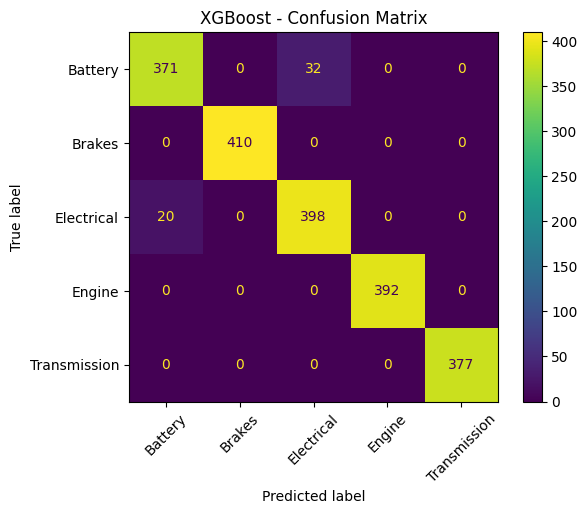

In [29]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_pred,
    display_labels=label_encoder.classes_,
    xticks_rotation=45
)

plt.title("XGBoost - Confusion Matrix")
plt.show()

In [30]:
comparison_df = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        dummy_accuracy,
        rf_accuracy,
        xgb_accuracy
    ],

    "Macro Precision": [
        dummy_precision,
        rf_precision,
        xgb_precision
    ],

    "Macro Recall": [
        dummy_recall,
        rf_recall,
        xgb_recall
    ],

    "Macro F1": [
        dummy_f1,
        rf_f1,
        xgb_f1
    ]
})

comparison_df

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Dummy Baseline,0.209,0.041800,0.200000,0.069148
1,Random Forest,0.973,0.974136,0.973522,0.973648
2,XGBoost,0.974,0.974886,0.974550,0.974638


In [31]:
comparison_percent = comparison_df.copy()

for col in [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]:
    comparison_percent[col] = (
        comparison_percent[col] * 100
    ).round(2)

comparison_percent

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Dummy Baseline,20.9,4.18,20.00,6.91
1,Random Forest,97.3,97.41,97.35,97.36
2,XGBoost,97.4,97.49,97.45,97.46


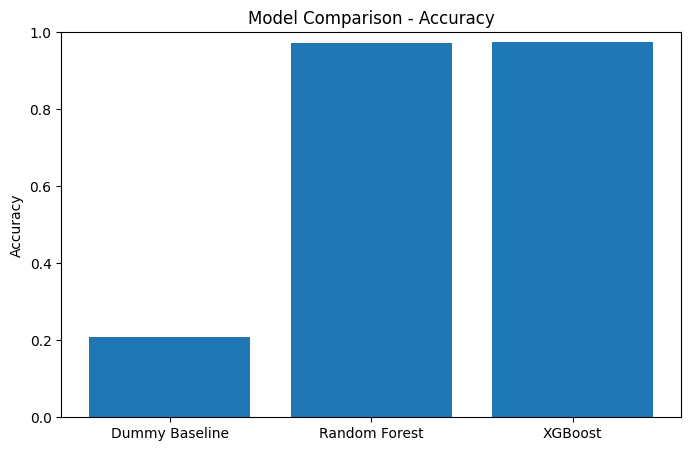

In [32]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"]
)

plt.title(
    "Model Comparison - Accuracy"
)

plt.ylabel(
    "Accuracy"
)

plt.ylim(0, 1)

plt.show()

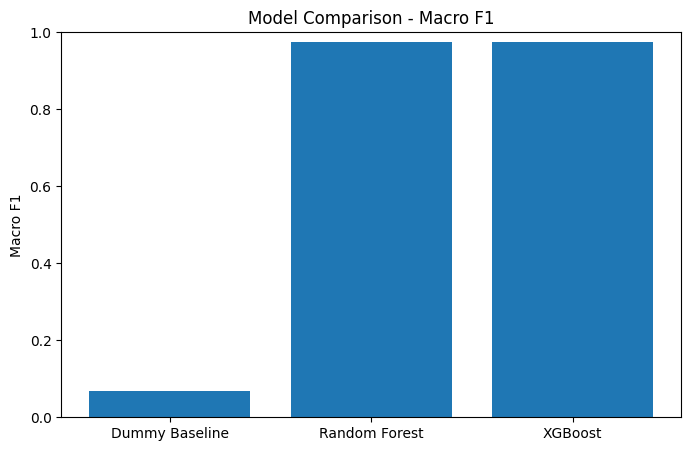

In [33]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Macro F1"]
)

plt.title(
    "Model Comparison - Macro F1"
)

plt.ylabel(
    "Macro F1"
)

plt.ylim(0, 1)

plt.show()

In [34]:
best_index = comparison_df["Macro F1"].idxmax()

best_model_name = comparison_df.loc[
    best_index,
    "Model"
]

best_macro_f1 = comparison_df.loc[
    best_index,
    "Macro F1"
]

print(
    "Best model:",
    best_model_name
)

print(
    "Best Macro F1:",
    round(best_macro_f1, 4)
)

Best model: XGBoost
Best Macro F1: 0.9746


In [35]:
results_dir = "/content/drive/MyDrive/AutoSenseAI/results"

os.makedirs(
    results_dir,
    exist_ok=True
)

In [36]:
comparison_df.to_csv(
    os.path.join(
        results_dir,
        "random_forest_vs_xgboost_comparison.csv"
    ),
    index=False
)

print("Comparison saved successfully")

Comparison saved successfully


In [37]:
model_dir = "/content/drive/MyDrive/AutoSenseAI/models"

os.makedirs(
    model_dir,
    exist_ok=True
)

In [38]:
rf_model_path = os.path.join(
    model_dir,
    "maintenance_category_enriched_random_forest.pkl"
)

joblib.dump(
    rf_pipeline,
    rf_model_path
)

print(
    "Random Forest model saved:",
    rf_model_path
)

Random Forest model saved: /content/drive/MyDrive/AutoSenseAI/models/maintenance_category_enriched_random_forest.pkl


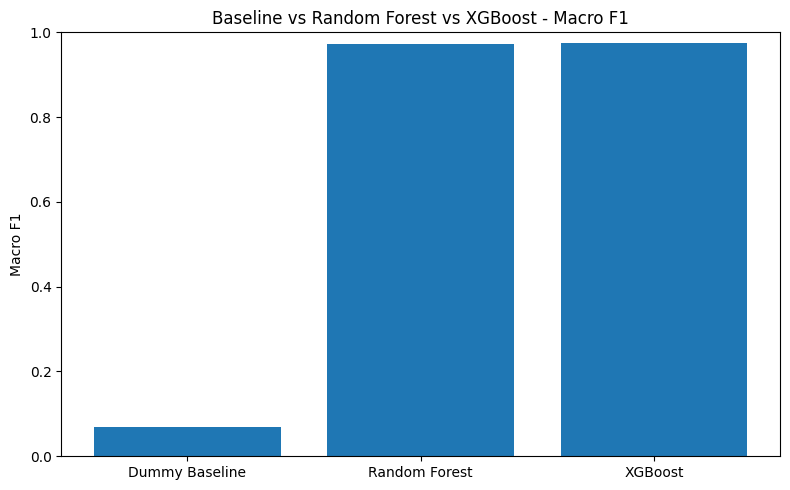

Saved: /content/drive/MyDrive/AutoSenseAI/results/model_macro_f1_comparison.png


In [39]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Macro F1"]
)

plt.title(
    "Baseline vs Random Forest vs XGBoost - Macro F1"
)

plt.ylabel(
    "Macro F1"
)

plt.ylim(0, 1)

plt.tight_layout()

macro_f1_path = os.path.join(
    results_dir,
    "model_macro_f1_comparison.png"
)

plt.savefig(
    macro_f1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", macro_f1_path)

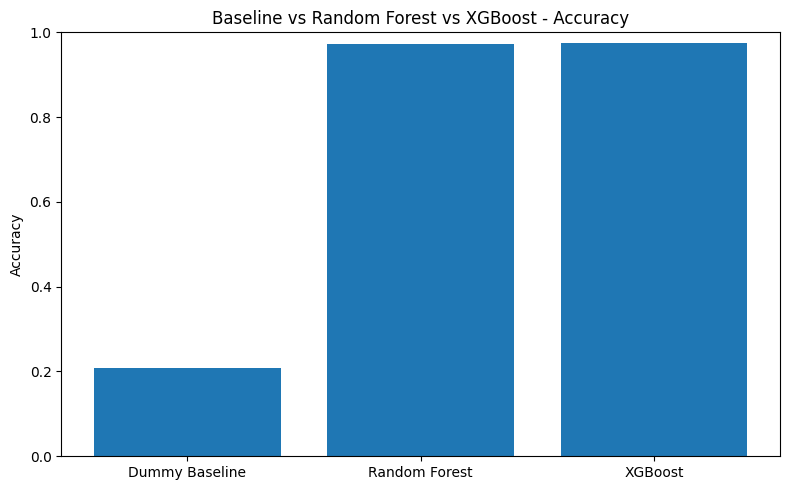

Saved: /content/drive/MyDrive/AutoSenseAI/results/model_accuracy_comparison.png


In [40]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"]
)

plt.title(
    "Baseline vs Random Forest vs XGBoost - Accuracy"
)

plt.ylabel(
    "Accuracy"
)

plt.ylim(0, 1)

plt.tight_layout()

accuracy_path = os.path.join(
    results_dir,
    "model_accuracy_comparison.png"
)

plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", accuracy_path)

In [41]:
rf_wrong = np.sum(
    rf_pred != y_test
)

xgb_wrong = np.sum(
    xgb_pred != y_test
)

print(
    "Random Forest wrong predictions:",
    rf_wrong
)

print(
    "XGBoost wrong predictions:",
    xgb_wrong
)

Random Forest wrong predictions: 54
XGBoost wrong predictions: 52


## Experiment Summary

Objective:
Compare a simple baseline, Random Forest and XGBoost for enriched
maintenance-category prediction.

Dataset:
ML Car Diagnostic Agent AI Assistant dataset.

Target:
Problem Classification.

Input Features:
- Car Make
- Car Model
- Vehicle Year
- Problem Description
- Severity
- Service History
- ECU Data
- Diagnosis

Models:
1. Dummy most-frequent baseline
2. Random Forest
3. XGBoost

Evaluation Metrics:
- Accuracy
- Macro Precision
- Macro Recall
- Macro F1

Model Selection Criterion:
Macro F1 is used as the primary selection metric because the task is
multi-class classification and performance across all maintenance
categories is important.

Final Result:
[Insert actual values.]

Selected Model:
[Insert winning model.]

Reason:
The selected model achieved the strongest Macro F1 under the same
train/test split and feature configuration.